In [1]:
%reset
import numpy as np
import matplotlib.pyplot as plt
import dnaMD
import fileinput as fi
import scipy
from scipy.optimize import curve_fit
from scipy.stats import linregress
from pylab import *
from tabulate import tabulate
%matplotlib inline

def rm_neun(vari):
    indizes = np.array([])
    for x in range(len(vari)):
        nmmr = np.where(vari[x] == 99.99)
        indizes = np.append(indizes,nmmr)

    indexes = np.sort(indizes)
    indexes = np.flip(indexes)
    indexes = indexes.astype(int)
    indexes = list(dict.fromkeys(indexes))
       
    for d in range(len(vari)):
        for y in range(len(indexes)):
            #print(indexes[y])
            vari[d] = np.delete(vari[d],indexes[y])
            
    return vari

Once deleted, variables cannot be recovered. Proceed (y/[n])? y


In [3]:
Ahel   =dnaMD.DNA(20);
ArealA =dnaMD.DNA(20);
Aprime =dnaMD.DNA(20);

Ahel.set_base_step_parameters('Ahel/L-BPS_Ahel.dat',parameters='all',bp_step=[1, 19],step_range=True,helical=False) ;
ArealA.set_base_step_parameters('Ahel_realA/L-BPS_realAhel.dat',parameters='all',bp_step=[1, 19],step_range=True,helical=False) ;
Aprime.set_base_step_parameters('Aprime/L-BPS_Aprime.dat',parameters='all',bp_step=[1, 19],step_range=True,helical=False) ;

Ahel.set_helical_radius('Ahel/HelixRad_Ahel.dat',atomname='C1*',bp=[1,19],bp_range=True);
ArealA.set_helical_radius('Ahel_realA/HelixRad_realAhel.dat',atomname='C1*',bp=[1,19],bp_range=True);
Aprime.set_helical_radius('Aprime/HelixRad_Aprime.dat',atomname='C1*',bp=[1,19],bp_range=True);

Ahel.set_base_pair_parameters('Ahel/L-BP_Ahel.dat',parameters='all',bp=[1,20],bp_range=True);
Aprime.set_base_pair_parameters('Aprime/L-BP_Aprime.dat',parameters='all',bp=[1,20],bp_range=True);
ArealA.set_base_pair_parameters('Ahel_realA/L-BP_realAhel.dat',parameters='all',bp=[1,20],bp_range=True);


rangen = [1,19]
Ahelrise, bp_idx = Ahel.get_parameters('rise',rangen,bp_range=True);
Aheltwist, bp_idx = Ahel.get_parameters('twist',rangen,bp_range=True);
Ahelroll, bp_idx = Ahel.get_parameters('roll',rangen,bp_range=True);
Ahelradius1, bp_idx = Ahel.get_parameters('radius s-1',rangen,bp_range=True); 
Ahelprop, bp_idx = Ahel.get_parameters('propeller',[1,20],bp_range=True); 

ArealArise, bp_idx = ArealA.get_parameters('rise',rangen,bp_range=True);
ArealAtwist, bp_idx = ArealA.get_parameters('twist',rangen,bp_range=True);
ArealAroll, bp_idx = ArealA.get_parameters('roll',rangen,bp_range=True);
ArealAradius1, bp_idx = ArealA.get_parameters('radius s-1',rangen,bp_range=True); 
ArealAprop, bp_idx = ArealA.get_parameters('propeller',[1,20],bp_range=True); 

Aprimerise, bp_idx = Aprime.get_parameters('rise',rangen,bp_range=True);
Aprimetwist, bp_idx = Aprime.get_parameters('twist',rangen,bp_range=True);
Aprimeroll, bp_idx = Aprime.get_parameters('roll',rangen,bp_range=True);
Aprimeradius1, bp_idx = Aprime.get_parameters('radius s-1',rangen,bp_range=True); 
Aprimeprop, bp_idx = Aprime.get_parameters('propeller',[1,20],bp_range=True); 

table = [['rise' ,str(round(mean(Ahelrise),2))    ,str(round(mean(ArealArise),2))          ,str(round(mean(Aprimerise),2)) ],\
                ['rad'  ,str(round(mean(Ahelradius1),2)) ,str(round(mean(ArealAradius1),2)),str(round(mean(Aprimeradius1),2))],\
                ['twist',str(round(mean(Aheltwist),1))   ,str(round(mean(ArealAtwist),1))  ,str(round(mean(Aprimetwist),1))  ],\
                ['inc'  ,str(round(mean(Ahelroll),1))     ,str(round(mean(ArealAroll),1))    ,str(round(mean(Aprimeroll),1))]]
print(tabulate( table,headers=['','Ahel','real Ahel','Aprime'])) 

print(str(round(mean(Ahelprop),2)))
print(str(round(mean(ArealAprop),2)))
print(str(round(mean(Aprimeprop),2)))
#print(mean(Ahelrise))
#print(mean(ArealArise))



Reading file : Ahel/L-BPS_Ahel.dat
Reading frame 0
Finished reading.... Total number of frame read =  1

Reading file : Ahel_realA/L-BPS_realAhel.dat
Reading frame 0
Finished reading.... Total number of frame read =  1

Reading file : Aprime/L-BPS_Aprime.dat
Reading frame 0
Finished reading.... Total number of frame read =  1

Reading file : Ahel/HelixRad_Ahel.dat
Reading frame 0
Finished reading.... Total number of frame read =  1

Reading file : Ahel_realA/HelixRad_realAhel.dat
Reading frame 0
Finished reading.... Total number of frame read =  1

Reading file : Aprime/HelixRad_Aprime.dat
Reading frame 0
Finished reading.... Total number of frame read =  1

Reading file : Ahel/L-BP_Ahel.dat
Reading frame 0
Finished reading.... Total number of frame read =  1

Reading file : Aprime/L-BP_Aprime.dat
Reading frame 0
Finished reading.... Total number of frame read =  1

Reading file : Ahel_realA/L-BP_realAhel.dat
Reading frame 0
Finished reading.... Total number of frame read =  1
       

In [18]:
bscdna=dnaMD.DNA(20);
#bscdna.set_base_step_parameters('PCA/DNA/tst.txt',parameters='all',bp_step=[1, 19],step_range=True,helical=True) 
bscdna.set_base_step_parameters('PCA/DNA/L-BPS_dna.dat',parameters='all',bp_step=[1, 19],step_range=True,helical=False) ;
bscrad = dnaMD.DNA(20) ;
bscrad.set_helical_radius('PCA/DNA/HelixRad_dna.dat',atomname='C1*',bp=[1,19],bp_range=True);
 
Deodd=dnaMD.DNA(20)
#Deodd.set_base_step_parameters('desresodd/L-BPH_tst.dat',parameters='all',bp_step=[1, 19],step_range=True,helical=True) 
Deodd.set_base_step_parameters('desreseven/L-BPS_g.dat',parameters='all',bp_step=[1, 19],step_range=True,helical=False) 
Deoddrad = dnaMD.DNA(20) 
#Deoddrad.set_helical_radius('desresodd/HelixRad_tst.dat',atomname='C1*',bp=[1,19],bp_range=True)
Deoddrad.set_helical_radius('desreseven/HelixRad_g.dat',atomname='C1*',bp=[1,19],bp_range=True)
Deoddprop = dnaMD.DNA(20) 
Deoddprop.set_base_pair_parameters('desreseven/L-BP_g.dat',parameters='all',bp=[1,20],bp_range=True)

DeV2=dnaMD.DNA(20)
DeV2.set_base_step_parameters('DESRESeven_v2_200ns/L-BPS_DEv2full.dat',parameters='all',bp_step=[1, 19],step_range=True,helical=False) 
DeV2rad = dnaMD.DNA(20) 
DeV2rad.set_helical_radius('DESRESeven_v2_200ns/HelixRad_DEv2full.dat',atomname='C1*',bp=[1,19],bp_range=True)
DeV2prop = dnaMD.DNA(20) 
DeV2prop.set_base_pair_parameters('DESRESeven_v2_200ns/L-BP_DEv2full.dat',parameters='all',bp=[1,20],bp_range=True)


ol3odd = dnaMD.DNA(20); ol3oddrad = dnaMD.DNA(20)
ol3odd.set_base_step_parameters('ol3-odd-v2/L-BPS_ol3.dat',parameters='all',bp_step=[1, 19],step_range=True,helical=False) 
ol3oddrad.set_helical_radius('ol3-odd-v2/HelixRad_ol3.dat',atomname='C1*',bp=[1,19],bp_range=True)
#ol3odd.set_base_step_parameters('ol3_even_new/L-BPH_ol3evnew.dat',parameters='all',bp_step=[1, 19],step_range=True,helical=True) 
#ol3oddrad.set_helical_radius('ol3_even_new/HelixRad_ol3evnew.dat',atomname='C1*',bp=[1,19],bp_range=True)
ol3oddprop = dnaMD.DNA(20) 
ol3oddprop.set_base_pair_parameters('ol3-odd-v2/L-BP_ol3.dat',parameters='all',bp=[1,20],bp_range=True)


#Deodd.set_base_step_parameters('desreseven/L-BPH_g.dat',parameters='all',bp_step=[1, 19],step_range=True,helical=True) 
chosi = "noplot"#dna,rna,both,DO,all, noplot

#rangen = [1,19]
#rangen = [9,12]
rangen = [5,16]
#rangen = [6,15]
Deoddrise, bp_idx = Deodd.get_parameters('rise',rangen,bp_range=True);avg_Deoddrise = np.mean(Deoddrise, axis=0)
Deoddtwist, bp_idx = Deodd.get_parameters('twist',rangen,bp_range=True);avg_Deoddtwist = np.mean(Deoddtwist, axis=0)
#Deoddx, bp_idx = Deodd.get_parameters('x-disp',rangen,bp_range=True);#avg_Deoddx = np.mean(Deoddx, axis=0)
#Deoddy, bp_idx = Deodd.get_parameters('y-disp',rangen,bp_range=True);#avg_Deoddy = np.mean(Deoddy, axis=0)
Deoddinc, bp_idx = Deodd.get_parameters('roll',rangen,bp_range=True);#avg_Deoddinc = np.mean(Deoddinc, axis=0)
Deoddradius1, bp_idx = Deoddrad.get_parameters('radius s-1',rangen,bp_range=True); #avg_Deoddradius1 = np.mean(Deoddradius1, axis=0)
Deoddpropeller, bp_idx = Deoddprop.get_parameters('propeller',[1,20],bp_range=True);

DeV2rise, bp_idx = DeV2.get_parameters('rise',rangen,bp_range=True);avg_DeV2rise = np.mean(Deoddrise, axis=0)
DeV2twist, bp_idx = DeV2.get_parameters('twist',rangen,bp_range=True);avg_DeV2twist = np.mean(Deoddtwist, axis=0)
#DeV2x, bp_idx = DeV2.get_parameters('x-disp',rangen,bp_range=True);#avg_DeV2x = np.mean(DeV2x, axis=0)
#DeV2y, bp_idx = DeV2.get_parameters('y-disp',rangen,bp_range=True);#avg_DeV2y = np.mean(DeV2y, axis=0)
DeV2inc, bp_idx = DeV2.get_parameters('roll',rangen,bp_range=True);#avg_DeV2inc = np.mean(DeV2inc, axis=0)
DeV2radius1, bp_idx = DeV2rad.get_parameters('radius s-1',rangen,bp_range=True); #avg_DeV2radius1 = np.mean(DeV2radius1, axis=0)
DeV2propeller, bp_idx = DeV2prop.get_parameters('propeller',[1,20],bp_range=True); 
    
bscdnarise, bp_idx = bscdna.get_parameters('rise',rangen,bp_range=True);avg_bscdnarise = np.mean(bscdnarise, axis=0)
bscdnatwist, bp_idx = bscdna.get_parameters('twist',rangen,bp_range=True);avg_bscdnatwist = np.mean(bscdnatwist, axis=0)
#bscdnax, bp_idx = bscdna.get_parameters('x-disp',rangen,bp_range=True);#avg_bscdnax = np.mean(bscdnax, axis=0)
#bscdnay, bp_idx = bscdna.get_parameters('y-disp',rangen,bp_range=True);#avg_bscdnay = np.mean(bscdnay, axis=0)
bscdnainc, bp_idx = bscdna.get_parameters('roll',rangen,bp_range=True);#avg_bscdnainc = np.mean(bscdnainc, axis=0)
bscdnaradius1, bp_idx = bscrad.get_parameters('radius s-1',rangen,bp_range=True); 

ol3oddrise, bp_idx = ol3odd.get_parameters('rise',rangen,bp_range=True);avg_ol3oddrise = np.mean(ol3oddrise, axis=0)
ol3oddtwist, bp_idx = ol3odd.get_parameters('twist',rangen,bp_range=True);avg_ol3oddtwist = np.mean(ol3oddtwist, axis=0)
#ol3oddx, bp_idx = ol3odd.get_parameters('x-disp',rangen,bp_range=True);
#ol3oddy, bp_idx = ol3odd.get_parameters('y-disp',rangen,bp_range=True);
ol3oddinc, bp_idx = ol3odd.get_parameters('roll',rangen,bp_range=True);
ol3oddradius1, bp_idx = ol3oddrad.get_parameters('radius s-1',rangen,bp_range=True); 
ol3oddpropeller, bp_idx = ol3oddprop.get_parameters('propeller',[1,20],bp_range=True); 

#ol3oddrise, bp_idx = ol3odd.get_parameters('rise',rangen,bp_range=True);avg_ol3oddrise = np.mean(ol3oddrise, axis=0)
#ol3oddtwist, bp_idx = ol3odd.get_parameters('twist',rangen,bp_range=True);avg_ol3oddtwist = np.mean(ol3oddtwist, axis=0)
#ol3oddx, bp_idx = ol3odd.get_parameters('roll',rangen,bp_range=True);
#ol3oddy, bp_idx = ol3odd.get_parameters('slide',rangen,bp_range=True);
#ol3oddinc, bp_idx = ol3odd.get_parameters('tilt',rangen,bp_range=True);


if chosi =="both":
    plt.figure(figsize=(12,8))
    subplot(2,2,1)
    plt.plot(bscdna.time/1000, avg_bscdnarise);plt.ylabel('Helical rise / $\AA$');
    plt.title('DNA bsc1')
    subplot(2,2,3)
    plt.plot(bscdna.time/1000, avg_bscdnatwist);plt.ylabel('Helical twist / °');plt.xlabel('time / ns');
    
    subplot(2,2,2)
    plt.plot(Deodd.time/1000, avg_Deoddrise); 
    plt.title('RNA DESRES odd')
    subplot(2,2,4)
    plt.plot(bscdna.time/1000, avg_Deoddtwist);plt.xlabel('time / ns');
    
elif chosi =="rna":
    subplot(2,1,1);    plt.plot(Deodd.time/1000, avg_Deoddrise);  plt.title('RNA DESRES odd')
    subplot(2,1,2);    plt.plot(bscdna.time/1000, avg_Deoddtwist);plt.xlabel('time / ns');

elif chosi =="dna":
    plt.plot(bscdna.time/1000, avg_bscdnarise); plt.xlabel('time / ns');plt.ylabel('Helical rise / $\AA$');plt.title('DNA bsc1')

elif chosi == "DO":
    plt.figure(figsize=(12,8))
    subplot(2,2,1)
    plt.plot(ol3odd.time/1000, avg_ol3oddrise);plt.ylabel('Helical rise / $\AA$');
    plt.title('RNA OL3 odd')
    subplot(2,2,3)
    plt.plot(ol3odd.time/1000, avg_ol3oddtwist);plt.ylabel('Helical twist / °');plt.xlabel('time / ns');
    
    subplot(2,2,2)
    plt.plot(Deodd.time/1000, avg_Deoddrise); 
    plt.title('RNA DESRES odd')
    subplot(2,2,4)
    plt.plot(bscdna.time/1000, avg_Deoddtwist);plt.xlabel('time / ns');

elif chosi == "all":
    plt.figure(figsize=(16,8))
    
    subplot(2,3,1)
    plt.plot(bscdna.time/1000, avg_bscdnarise);plt.ylabel('Helical rise / $\AA$');
    plt.title('DNA bsc1')
    subplot(2,3,4)
    plt.plot(bscdna.time/1000, avg_bscdnatwist);plt.ylabel('Helical twist / °');plt.xlabel('time / ns');
    
    subplot(2,3,2)
    plt.plot(ol3odd.time/1000, avg_ol3oddrise);plt.ylabel('Helical rise / $\AA$');
    plt.title('RNA OL3 odd')
    subplot(2,3,5)
    plt.plot(ol3odd.time/1000, avg_ol3oddtwist);plt.ylabel('Helical twist / °');plt.xlabel('time / ns');
    
    subplot(2,3,3)
    plt.plot(Deodd.time/1000, avg_Deoddrise); 
    plt.title('RNA DESRES odd')
    subplot(2,3,6)
    plt.plot(bscdna.time/1000, avg_Deoddtwist);plt.xlabel('time / ns');
    



Reading file : PCA/DNA/L-BPS_dna.dat
Reading frame 2000
Finished reading.... Total number of frame read =  2001

Reading file : PCA/DNA/HelixRad_dna.dat
Reading frame 2000
Finished reading.... Total number of frame read =  2001

Reading file : desreseven/L-BPS_g.dat
Reading frame 2000
Finished reading.... Total number of frame read =  2001

Reading file : desreseven/HelixRad_g.dat
Reading frame 2000
Finished reading.... Total number of frame read =  2001

Reading file : desreseven/L-BP_g.dat
Reading frame 2000
Finished reading.... Total number of frame read =  2001

Reading file : DESRESeven_v2_200ns/L-BPS_DEv2full.dat
Reading frame 2000
Finished reading.... Total number of frame read =  2001

Reading file : DESRESeven_v2_200ns/HelixRad_DEv2full.dat
Reading frame 2000
Finished reading.... Total number of frame read =  2001

Reading file : DESRESeven_v2_200ns/L-BP_DEv2full.dat
Reading frame 2000
Finished reading.... Total number of frame read =  2001

Reading file : ol3-odd-v2/L-BPS_ol

dna: -0.001         ; r-value: -0.01
OL3: -0.038         ; r-value: -0.47
Desres: -0.035     ; r-value: -0.46
Desres v2: -0.018  ; r-value: -0.24
         DNA    OL3    DESRES    DESRES v2
-----  -----  -----  --------  -----------
rise    3.32   3.31      3.35         3.29
rad     6.24   8.73      9.35         9.27
twist  34.6   30.3      28.9         29.29
roll    1.9    7         5.1          6.24

twist: 30.27°


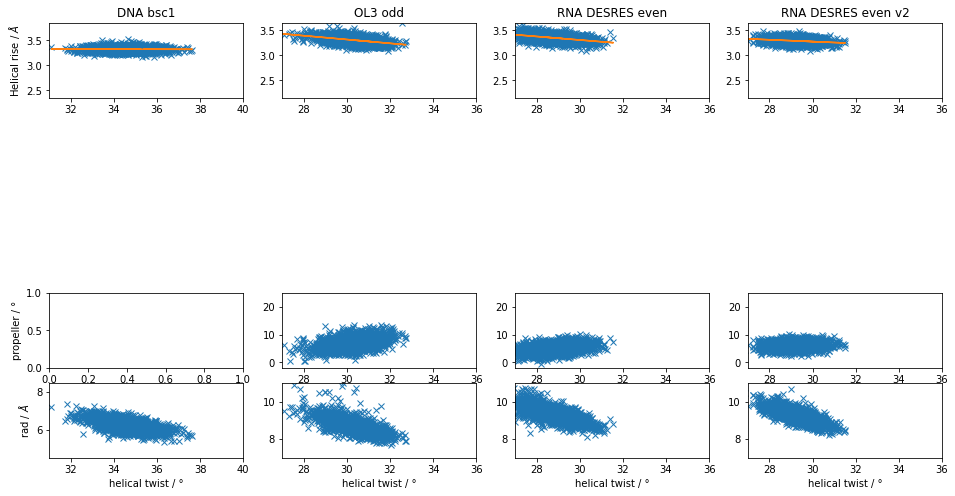

In [20]:
bscdnarise = rm_neun(bscdnarise); avg_bscdnarise = np.mean(bscdnarise, axis=0)
bscdnatwist = rm_neun(bscdnatwist); avg_bscdnatwist = np.mean(bscdnatwist, axis=0)
#bscdnax = rm_neun(bscdnax); avg_bscdnax = np.mean(bscdnax, axis=0)
#bscdnay = rm_neun(bscdnay); avg_bscdnay = np.mean(bscdnay, axis=0)
bscdnainc = rm_neun(bscdnainc); avg_bscdnainc = np.mean(bscdnainc, axis=0)
bscdnaradius1 = rm_neun(bscdnaradius1); avg_bscdnaradius1 = np.mean(bscdnaradius1, axis=0)
bscdna.time = bscdna.time[0:len(bscdnatwist[0])]

Deoddrise = rm_neun(Deoddrise); avg_Deoddrise = np.mean(Deoddrise, axis=0)
Deoddtwist = rm_neun(Deoddtwist); avg_Deoddtwist = np.mean(Deoddtwist, axis=0)
#Deoddx = rm_neun(Deoddx); avg_Deoddx = np.mean(Deoddx, axis=0)
#Deoddy = rm_neun(Deoddy); avg_Deoddy = np.mean(Deoddy, axis=0)
Deoddinc = rm_neun(Deoddinc); avg_Deoddinc = np.mean(Deoddinc, axis=0)
Deoddradius1 = rm_neun(Deoddradius1); avg_Deoddradius1 = np.mean(Deoddradius1, axis=0)
Deoddpropeller= rm_neun(Deoddpropeller); avg_Deoddpropeller= np.mean(Deoddpropeller, axis=0)

DeV2rise = rm_neun(DeV2rise); avg_DeV2rise = np.mean(DeV2rise, axis=0)
DeV2twist = rm_neun(DeV2twist); avg_DeV2twist = np.mean(DeV2twist, axis=0)
#DeV2x = rm_neun(DeV2x); avg_DeV2x = np.mean(DeV2x, axis=0)
#DeV2y = rm_neun(DeV2y); avg_DeV2y = np.mean(DeV2y, axis=0)
DeV2inc = rm_neun(DeV2inc); avg_DeV2inc = np.mean(DeV2inc, axis=0)
DeV2radius1 = rm_neun(DeV2radius1); avg_DeV2radius1 = np.mean(DeV2radius1, axis=0)
DeV2propeller= rm_neun(DeV2propeller); avg_DeV2propeller= np.mean(DeV2propeller, axis=0)

ol3oddrise = rm_neun(ol3oddrise); 
avg_ol3oddrise = np.mean(ol3oddrise, axis=0)
ol3oddtwist = rm_neun(ol3oddtwist); 
avg_ol3oddtwist = np.mean(ol3oddtwist, axis=0)
#ol3oddx = rm_neun(ol3oddx); avg_ol3oddx = np.mean(ol3oddx, axis=0)
#ol3oddy = rm_neun(ol3oddy); avg_ol3oddy = np.mean(ol3oddy, axis=0)
ol3oddinc = rm_neun(ol3oddinc); avg_ol3oddinc = np.mean(ol3oddinc, axis=0)
ol3oddradius1 = rm_neun(ol3oddradius1); avg_ol3oddradius1 = np.mean(ol3oddradius1, axis=0)
ol3oddpropeller= rm_neun(ol3oddpropeller); avg_ol3oddpropeller= np.mean(ol3oddpropeller, axis=0)

Deodd.time = Deodd.time[0:len(Deoddtwist[0])]


#m_dna,b_dna = np.polyfit(avg_bscdnatwist,avg_bscdnarise,1)
#m_Des,b_Des = np.polyfit(avg_Deoddtwist,avg_Deoddrise,1)
#m_DesV2,b_DesV2 = np.polyfit(avg_DeV2twist,avg_DeV2rise,1)
#m_OL,b_OL = np.polyfit(avg_ol3oddtwist,avg_ol3oddrise,1)

m_dna,b_dna,r_dna,p_dna,stderr_dna= linregress(avg_bscdnatwist,avg_bscdnarise)
m_Des,b_Des,r_Des,p_Des,stderr_Des= linregress(avg_Deoddtwist,avg_Deoddrise)
m_DesV2,b_DesV2,r_DesV2,p_DesV2,stderr_DesV2= linregress(avg_DeV2twist,avg_DeV2rise)
m_OL,b_OL,r_OL,p_OL,stderr_OL= linregress(avg_ol3oddtwist,avg_ol3oddrise)


cudof = 10
chosi = "all"#rna, dna, both, DO

plt.figure(figsize=(16,8))
subplot(5,4,1);    plt.plot(avg_bscdnatwist[0:len(avg_DeV2twist)-cudof],avg_bscdnarise[0:len(avg_DeV2twist)-cudof],'x'); plt.ylabel('Helical rise / $\AA$');plt.title('DNA bsc1'); 
plt.axis([31, 40, 2.35, 3.85])
plt.plot(avg_bscdnatwist,(m_dna*avg_bscdnatwist+b_dna));
#subplot(5,4,5);    plt.plot(avg_bscdnatwist[0:len(avg_DeV2twist)-cudof],avg_bscdnax[0:len(avg_DeV2twist)-cudof],'x'); plt.ylabel('x-disp / $\AA$');
#plt.axis([31, 40, -3, 1.5])
#subplot(5,4,9);    plt.plot(avg_bscdnatwist[0:len(avg_DeV2twist)-cudof],avg_bscdnay[0:len(avg_DeV2twist)-cudof],'x'); plt.ylabel('y-disp / $\AA$');
#plt.axis([31, 40, -1.75, 1.75])
#subplot(5,4,13);    plt.plot(avg_bscdnatwist[0:len(avg_DeV2twist)-cudof],avg_bscdnainc[0:len(avg_DeV2twist)-cudof],'x'); 
subplot(5,4,13); plt.ylabel('propeller / °');#plt.axis([31, 40, -10, 17])
subplot(5,4,17);    plt.plot(avg_bscdnatwist[0:len(avg_DeV2twist)-cudof],avg_bscdnaradius1[0:len(avg_DeV2twist)-cudof],'x'); plt.ylabel('rad / $\AA$');plt.xlabel('helical twist / °');
plt.axis([31, 40, 4.5,8.5])

subplot(5,4,2);    plt.plot(avg_ol3oddtwist[0:len(avg_DeV2twist)-cudof],avg_ol3oddrise[0:len(avg_DeV2twist)-cudof],'x'); 
plt.title('OL3 odd'); 
#plt.title('DESRES even v2'); 
plt.axis([27, 36, 2.15, 3.65])
plt.plot(avg_ol3oddtwist,(m_OL*avg_ol3oddtwist+b_OL));
#subplot(5,4,6);    plt.plot(avg_ol3oddtwist[0:len(avg_DeV2twist)-cudof],avg_ol3oddx[0:len(avg_DeV2twist)-cudof],'x'); plt.axis([27, 36, -7, -2.5])
#subplot(5,4,10);    plt.plot(avg_ol3oddtwist[0:len(avg_DeV2twist)-cudof],avg_ol3oddy[0:len(avg_DeV2twist)-cudof],'x'); plt.axis([27, 36, -1.8, 1.7])
subplot(5,4,14);    plt.plot(avg_ol3oddtwist[0:len(avg_DeV2twist)-cudof],avg_ol3oddinc[0:len(avg_DeV2twist)-cudof],'x'); plt.xlabel('helical twist / °');
plt.axis([27, 36, -2, 25])
#subplot(5,4,14);    plt.plot(avg_ol3oddtwist[0:len(avg_ol3oddtwist)-cudof],avg_ol3oddpropeller[0:len(avg_ol3oddtwist)-cudof],'x'); plt.xlabel('helical twist / °');
#plt.axis([27, 36, -20, 0])
subplot(5,4,18);    plt.plot(avg_ol3oddtwist[0:len(avg_ol3oddtwist)-cudof],avg_ol3oddradius1[0:len(avg_ol3oddtwist)-cudof],'x'); plt.xlabel('helical twist / °');
plt.axis([27,36 ,7, 11])

subplot(5,4,3);    plt.plot(avg_Deoddtwist[0:len(avg_DeV2twist)-cudof],avg_Deoddrise[0:len(avg_DeV2twist)-cudof],'x'); 
plt.title('RNA DESRES even');
plt.axis([27, 36, 2.15, 3.65]) #plt.axis([26, 35, 2.25, 3.75])
plt.plot(avg_Deoddtwist,(m_Des*avg_Deoddtwist+b_Des));
#subplot(5,4,7);    plt.plot(avg_Deoddtwist[0:len(avg_DeV2twist)-cudof],avg_Deoddx[0:len(avg_DeV2twist)-cudof],'x');plt.axis([26, 35, -8, -3.5])
#subplot(5,4,11);    plt.plot(avg_Deoddtwist[0:len(avg_DeV2twist)-cudof],avg_Deoddy[0:len(avg_DeV2twist)-cudof],'x'); plt.axis([26, 35, -1.8, 1.7])
subplot(5,4,15);    plt.plot(avg_Deoddtwist[0:len(avg_DeV2twist)-cudof],avg_Deoddinc[0:len(avg_DeV2twist)-cudof],'x'); plt.xlabel('helical twist / °');
plt.axis([27, 36, -2, 25])#plt.axis([26, 35, -5, 22])
#subplot(5,4,15);    plt.plot(avg_Deoddtwist[0:len(avg_DeV2twist)-cudof],avg_Deoddpropeller[0:len(avg_DeV2twist)-cudof],'x'); plt.xlabel('helical twist / °');
#plt.axis([27, 36, -20, 0])#plt.axis([26, 35, -5, 22])
subplot(5,4,19);    plt.plot(avg_Deoddtwist[0:len(avg_DeV2twist)-cudof],avg_Deoddradius1[0:len(avg_DeV2twist)-cudof],'x'); plt.xlabel('helical twist / °');
plt.axis([27,36 ,7, 11]) #plt.axis([26,35 ,8, 12])

subplot(5,4,4);    plt.plot(avg_DeV2twist[0:len(avg_DeV2twist)-cudof],avg_DeV2rise[0:len(avg_DeV2twist)-cudof],'x'); 
plt.title('RNA DESRES even v2'); plt.axis([27, 36, 2.15, 3.65]) #plt.axis([26, 35, 2.25, 3.75])
plt.plot(avg_DeV2twist,(m_DesV2*avg_DeV2twist+b_DesV2));
#subplot(5,4,8);    plt.plot(avg_DeV2twist[0:len(avg_DeV2twist)-cudof],avg_DeV2x[0:len(avg_DeV2twist)-cudof],'x');plt.axis([26, 35, -8, -3.5])
#subplot(5,4,12);    plt.plot(avg_DeV2twist[0:len(avg_DeV2twist)-cudof],avg_DeV2y[0:len(avg_DeV2twist)-cudof],'x'); plt.axis([26, 35, -1.8, 1.7])
subplot(5,4,16);    plt.plot(avg_DeV2twist[0:len(avg_DeV2twist)-cudof],avg_DeV2inc[0:len(avg_DeV2twist)-cudof],'x'); plt.xlabel('helical twist / °');
plt.axis([27, 36, -2, 25])#plt.axis([26, 35, -5, 22])
#subplot(5,4,16);    plt.plot(avg_DeV2twist[0:len(avg_DeV2twist)-cudof],avg_DeV2propeller[0:len(avg_DeV2twist)-cudof],'x'); plt.xlabel('helical twist / °');
#plt.axis([27, 36, -20,0])
subplot(5,4,20);    plt.plot(avg_DeV2twist[0:len(avg_DeV2twist)-cudof],avg_DeV2radius1[0:len(avg_DeV2twist)-cudof],'x'); plt.xlabel('helical twist / °');
plt.axis([27,36 ,7, 11]) #plt.axis([26,35 ,8, 12])

              
print('dna: '+str(round(m_dna,3))+'         ; r-value: '+ str(round(r_dna,2)))
print('OL3: '+str(round(m_OL,3))+'         ; r-value: '+ str(round(r_OL,2)))    
print('Desres: '+str(round(m_Des,3))+'     ; r-value: '+ str(round(r_Des,2)))   
print('Desres v2: '+str(round(m_DesV2,3))+'  ; r-value: '+ str(round(r_DesV2,2)))    


table = [['rise' ,str(round(mean(avg_bscdnarise),2))    ,str(round(mean(avg_ol3oddrise),2))          ,str(round(mean(avg_Deoddrise),2))   ,str(round(mean(avg_DeV2rise),2)) ],\
                ['rad'  ,str(round(mean(avg_bscdnaradius1),2)) ,str(round(mean(avg_ol3oddradius1),2)),str(round(mean(avg_Deoddradius1),2)),str(round(mean(avg_DeV2radius1),2)) ],\
                ['twist',str(round(mean(avg_bscdnatwist),1))   ,str(round(mean(avg_ol3oddtwist),1))  ,str(round(mean(avg_Deoddtwist),1))  ,str(round(mean(avg_DeV2twist),2))    ],\
                ['roll'  ,str(round(mean(avg_bscdnainc),1))     ,str(round(mean(avg_ol3oddinc),1))    ,str(round(mean(avg_Deoddinc),1))    ,str(round(mean(avg_DeV2inc),2))     ]]
print(tabulate( table,headers=['','DNA','OL3','DESRES','DESRES v2'])) 
               #headers=['','DNA','OL3','DESRES']))

#nom = "table_range_%d_%d.txt" %(rangen[0],rangen[1])
#nom = "table_range_%d_%d.txt" %(rangen[0],rangen[1])
#with open(nom, 'w') as f:
#    f.write(tabulate(table,headers=['','DNA','OL3','DESRES','DESRES v2']))
#    f.write('\n\ntwist-stretch correlation slope'+'\nDNA: '+str(round(m_dna,3)) + '\nOL3: '+str(round(m_OL,3))\
#            + '\nDesres: '+str(round(m_Des,3)) + '\nDesres v2: '+str(round(m_DesV2,3)))

#fignom = "correlations_range_%d_%d.png" %(rangen[0],rangen[1])
    
    
#print(str(round(mean(avg_ol3oddpropeller),2)))
#print(str(round(mean(avg_Deoddpropeller),2)))
#print(str(round(mean(avg_DeV2propeller),2)))

#plt.savefig(fignom,dpi=1200)
#plt.savefig('correlations_bsc1DNA_OL3_DESRES_RNA.png',dpi=1200)

#m_D,b_D = curve_fit(lambda x,a:x*a, avg_Deoddtwist, avg_Deoddrise)
#print(m_D)
#m_Dsci,b_Dsci,r_value,p_value,std_err= linregress(avg_Deoddtwist,avg_Deoddrise)
#print(m_Dsci)
#print(r_value)
print('\ntwist: '+str(round(mean(avg_ol3oddtwist),2)) + '°')
#print('roll:  '+str(round(mean(avg_ol3oddx),2)))
#print('slide: '+str(round(mean(avg_ol3oddy),2)))
#print(str(mean(avg_ol3oddtwist[-2000:-1])))


In [16]:
# Careful! only use once to add a line of 99.99 to timesteps where
# a basepair is missing
#fff

#dateenamee = "desresodd/L-BPH_tst.dat"  #h-twist
#dateenamee = "desreseven/L-BPH_g.dat"  #h-twist
#dateenamee = "desresodd/L-BPS_tst.dat"  #just twist
#dateenamee = "desresodd/L-BP_tst.dat"  #stretch, hier diffe ==21 chekcne
#dateenamee = "PCA/DNA/tst.txt"
#dateenamee = "PCA/DNA/L-BPH_dna.dat"
#dateenamee = "PCA/DNA/MGroove_dna.dat"
#dateenamee = "ol3-odd-v2/L-BPH_ol3.dat"
#dateenamee = "ol3-odd-v2/HelixRad_ol3.dat"
#dateenamee = "ol3_even_new/HelixRad_ol3evnew.dat"
#dateenamee = "DESRESeven_v2/HelixRad_DEevenV2.dat"
#dateenamee = "DESRESeven_v2/L-BPH_DEevenV2.dat"
#dateenamee = "desreseven/frams/L-BPH_extfull.dat"
#dateenamee = "desreseven/frams/HelixRad_extfull.dat"
dateenamee="DESRESeven_v2_200ns/L-BPS_DEv2full.dat"

numb = "# Time ="#'99.99'
liste = np.array([])

with open(dateenamee) as myFile:
    for num, line in enumerate(myFile, 1):
        if numb in line:
            liste = np.append(liste,num)

diffe = np.diff(liste)
result = np.where(diffe == 20) #for base pair steps
#result = np.where(diffe == 21) #for base pairs
#result = np.where(diffe == 36)
result = result[0]

for x in result:
    if x==0:
        srch = '# Time =         0.00000'
        rplc = '# Time =         0.00000\n99.99   99.99   99.99   99.99   99.99   99.99'
    elif x>0 and x<10:
        srch = '# Time =       '+str(x)+'00.00000'
        rplc = '# Time =       '+str(x)+'00.00000\n99.99   99.99   99.99   99.99   99.99   99.99'
    elif x>9 and x<100:
        srch = '# Time =      '+str(x)+'00.00000'
        rplc = '# Time =      '+str(x)+'00.00000\n99.99   99.99   99.99   99.99   99.99   99.99'
    elif x>99 and x<1000:
        srch = '# Time =     '+str(x)+'00.00000'
        rplc = '# Time =     '+str(x)+'00.00000\n99.99   99.99   99.99   99.99   99.99   99.99'
    elif x>999 and x<10000:
        srch = '# Time =    '+str(x)+'00.00000'
        rplc = '# Time =    '+str(x)+'00.00000\n99.99   99.99   99.99   99.99   99.99   99.99'
        
    with fi.FileInput(dateenamee, inplace=True) as File:
        for line in File:
            print(line.replace(srch, rplc),end='')
            
result19 = np.where(diffe == 19) #for base pair steps
#result19 = np.where(diffe == 20) #for base pairs
#result19 = np.where(diffe == 35)
result19 = result19[0]

for y in result19:
    if y==0:
        srch = '# Time =         0.00000'
        rplc = '# Time =         0.00000\n99.99   99.99   99.99   99.99   99.99   99.99\n99.99   99.99   99.99   99.99   99.99   99.99'
    elif y>0 and y<10:
        srch = '# Time =       '+str(y)+'00.00000'
        rplc = '# Time =       '+str(y)+'00.00000\n99.99   99.99   99.99   99.99   99.99   99.99\n99.99   99.99   99.99   99.99   99.99   99.99'
    elif y>9 and y<100:
        srch = '# Time =      '+str(y)+'00.00000'
        rplc = '# Time =      '+str(y)+'00.00000\n99.99   99.99   99.99   99.99   99.99   99.99\n99.99   99.99   99.99   99.99   99.99   99.99'
    elif y>99 and y<1000:
        srch = '# Time =     '+str(y)+'00.00000'
        rplc = '# Time =     '+str(y)+'00.00000\n99.99   99.99   99.99   99.99   99.99   99.99\n99.99   99.99   99.99   99.99   99.99   99.99'
    elif y>999 and y<10000:
        srch = '# Time =    '+str(y)+'00.00000'
        rplc = '# Time =    '+str(y)+'00.00000\n99.99   99.99   99.99   99.99   99.99   99.99\n99.99   99.99   99.99   99.99   99.99   99.99'
        
    with fi.FileInput(dateenamee, inplace=True) as File:
        for line in File:
            print(line.replace(srch, rplc),end='')

In [8]:
## DNA File Zeiten umschreiben
with open('PCA/DNA/L-BPS_dna.dat', 'r') as file:
    data = file.readlines()

liste = liste.astype(int)
for x in liste:
    d = int(np.where(liste == x)[0])
    if d==0:
        data[x-1] = '# Time =         0.00000\n'
    elif d>0 and d<10:
        data[x-1] = '# Time =       '+str(d)+'00.00000\n'
        
    elif d>9 and d<100:
        data[x-1] = '# Time =      '+str(d)+'00.00000\n'
        
    elif d>99 and d<1000:
        data[x-1] = '# Time =     '+str(d)+'00.00000\n'
        
    elif d>999 and d<10000:
        data[x-1] = '# Time =    '+str(d)+'00.00000\n'
        
with open('PCA/DNA/L-BPS_dna.dat', 'w') as file:
    file.writelines( data )

In [303]:
indizes = np.array([])
for x in range(len(h_twist)): #19
    nmmr = np.where(h_twist[x] == 99.99)
    indizes = np.append(indizes,nmmr)
    
indexes = np.sort(indizes)
indexes = np.flip(indexes)
indexes = indexes.astype(int)
indexes = list(dict.fromkeys(indexes))   
    
for d in range(len(h_twist)): #19
    for y in range(len(indexes)):
        h_twist[d] = np.delete(h_twist[d],indexes[y])
        h_rise[d] = np.delete(h_rise[d],indexes[y])
        

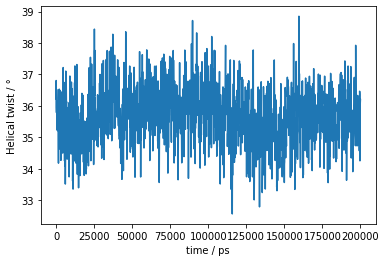

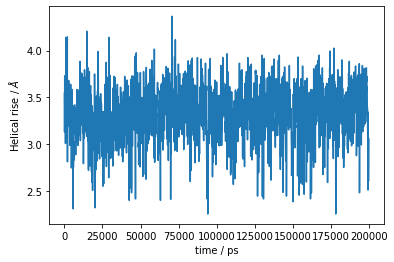

In [310]:
h_twist, bp_idx = De.get_parameters('h-twist',[5,16],bp_range=True)
h_rise, bp_idx = De.get_parameters('h-rise',[5,16],bp_range=False)
avg_h_twist = np.mean(h_twist, axis=0); plt.plot(De.time, avg_h_twist); plt.xlabel('time / ps'); plt.ylabel('Helical twist / °')
plt.show()
avg_h_rise = np.mean(h_rise, axis=0); plt.plot(De.time, avg_h_rise); plt.xlabel('time / ps'); plt.ylabel('Helical rise / $\AA$')
plt.show()


Reading file : desreseven/L-BPH_g.dat
Reading frame 2000
Finished reading.... Total number of frame read =  2001

Reading file : desreseven/HelixRad_g.dat
Reading frame 2000
Finished reading.... Total number of frame read =  2001

Reading file : desreseven/frams/L-BPH_extfull.dat
Reading frame 2000
Finished reading.... Total number of frame read =  2001

Reading file : desreseven/frams/HelixRad_extfull.dat
Reading frame 2000
Finished reading.... Total number of frame read =  2001
EXT: -0.068        ; r-value: -0.43
Desres: -0.062     ; r-value: -0.39


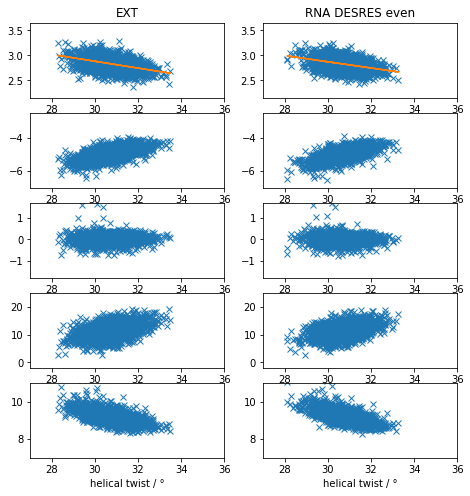

In [76]:
Deodd=dnaMD.DNA(20)
Deodd.set_base_step_parameters('desreseven/L-BPH_g.dat',parameters='all',bp_step=[1, 19],step_range=True,helical=True) 
Deoddrad = dnaMD.DNA(20) 
Deoddrad.set_helical_radius('desreseven/HelixRad_g.dat',atomname='C1*',bp=[1,19],bp_range=True)

EXT=dnaMD.DNA(36)
EXT.set_base_step_parameters('desreseven/frams/L-BPH_extfull.dat',parameters='all',bp_step=[1, 35],step_range=True,helical=True) 
EXTRAD= dnaMD.DNA(36) 
EXTRAD.set_helical_radius('desreseven/frams/HelixRad_extfull.dat',atomname='C1*',bp=[1,35],bp_range=True)

rangen = [1,19]
rangenEXT = [1,35]

Deoddrise, bp_idx = Deodd.get_parameters('h-rise',rangen,bp_range=True);avg_Deoddrise = np.mean(Deoddrise, axis=0)
Deoddtwist, bp_idx = Deodd.get_parameters('h-twist',rangen,bp_range=True);avg_Deoddtwist = np.mean(Deoddtwist, axis=0)
Deoddx, bp_idx = Deodd.get_parameters('x-disp',rangen,bp_range=True);#avg_Deoddx = np.mean(Deoddx, axis=0)
Deoddy, bp_idx = Deodd.get_parameters('y-disp',rangen,bp_range=True);#avg_Deoddy = np.mean(Deoddy, axis=0)
Deoddinc, bp_idx = Deodd.get_parameters('inclination',rangen,bp_range=True);#avg_Deoddinc = np.mean(Deoddinc, axis=0)
Deoddradius1, bp_idx = Deoddrad.get_parameters('radius s-1',rangen,bp_range=True); #avg_Deoddradius1 = np.mean(Deoddradius1, axis=0)

Extrise, bp_idx = EXT.get_parameters('h-rise',rangen,bp_range=True);avg_Extrise = np.mean(Extrise, axis=0)
Exttwist, bp_idx = EXT.get_parameters('h-twist',rangen,bp_range=True);avg_Exttwist = np.mean(Exttwist, axis=0)
Extx, bp_idx = EXT.get_parameters('x-disp',rangen,bp_range=True);#avg_Extx = np.mean(Extx, axis=0)
Exty, bp_idx = EXT.get_parameters('y-disp',rangen,bp_range=True);#avg_Exty = np.mean(Exty, axis=0)
Extinc, bp_idx = EXT.get_parameters('inclination',rangen,bp_range=True);#avg_Extinc = np.mean(Extinc, axis=0)
Extradius1, bp_idx = EXTRAD.get_parameters('radius s-1',rangen,bp_range=True); #avg_Extradius1 = np.mean(Extradius1, axis=0)

Deoddrise = rm_neun(Deoddrise); avg_Deoddrise = np.mean(Deoddrise, axis=0)
Deoddtwist = rm_neun(Deoddtwist); avg_Deoddtwist = np.mean(Deoddtwist, axis=0)
Deoddx = rm_neun(Deoddx); avg_Deoddx = np.mean(Deoddx, axis=0)
Deoddy = rm_neun(Deoddy); avg_Deoddy = np.mean(Deoddy, axis=0)
Deoddinc = rm_neun(Deoddinc); avg_Deoddinc = np.mean(Deoddinc, axis=0)
Deoddradius1 = rm_neun(Deoddradius1); avg_Deoddradius1 = np.mean(Deoddradius1, axis=0)

Extrise = rm_neun(Extrise); avg_Extrise = np.mean(Extrise, axis=0)
Exttwist = rm_neun(Exttwist); avg_Exttwist = np.mean(Exttwist, axis=0)
Extx = rm_neun(Extx); avg_Extx = np.mean(Extx, axis=0)
Exty = rm_neun(Exty); avg_Exty = np.mean(Exty, axis=0)
Extinc = rm_neun(Extinc); avg_Extinc = np.mean(Extinc, axis=0)
Extradius1 = rm_neun(Extradius1); avg_Extradius1 = np.mean(Extradius1, axis=0)


Deodd.time = Deodd.time[0:len(Deoddtwist[0])]

#m_dna,b_dna,r_dna,p_dna,stderr_dna= linregress(avg_bscdnatwist,avg_bscdnarise)
m_Des,b_Des,r_Des,p_Des,stderr_Des= linregress(avg_Deoddtwist,avg_Deoddrise)
#m_DesV2,b_DesV2,r_DesV2,p_DesV2,stderr_DesV2= linregress(avg_DeV2twist,avg_DeV2rise)
m_EXT,b_EXT,r_EXT,p_EXT,stderr_EXT= linregress(avg_Exttwist,avg_Extrise)


cudof = 10
chosi = "all"#rna, dna, both, DO

plt.figure(figsize=(16,8))
#subplot(5,4,1);    plt.plot(avg_bscdnatwist[0:len(avg_DeV2twist)-cudof],avg_bscdnarise[0:len(avg_DeV2twist)-cudof],'x'); plt.ylabel('Helical rise / $\AA$');plt.title('DNA bsc1'); plt.axis([31, 40, 2.35, 3.85])
#plt.plot(avg_bscdnatwist,(m_dna*avg_bscdnatwist+b_dna));
#subplot(5,4,5);    plt.plot(avg_bscdnatwist[0:len(avg_DeV2twist)-cudof],avg_bscdnax[0:len(avg_DeV2twist)-cudof],'x'); plt.ylabel('x-disp / $\AA$');plt.axis([32, 39, -3, 1.5])
#subplot(5,4,9);    plt.plot(avg_bscdnatwist[0:len(avg_DeV2twist)-cudof],avg_bscdnay[0:len(avg_DeV2twist)-cudof],'x'); plt.ylabel('y-disp / $\AA$');plt.axis([32, 39, -1.75, 1.75])
#subplot(5,4,13);    plt.plot(avg_bscdnatwist[0:len(avg_DeV2twist)-cudof],avg_bscdnainc[0:len(avg_DeV2twist)-cudof],'x'); plt.ylabel('inclination / °');plt.xlabel('helical twist / °');plt.axis([32, 39, -10, 17])
#subplot(5,4,17);    plt.plot(avg_bscdnatwist[0:len(avg_DeV2twist)-cudof],avg_bscdnaradius1[0:len(avg_DeV2twist)-cudof],'x'); plt.ylabel('rad / $\AA$');plt.xlabel('helical twist / °');plt.axis([32,39, 4.5,8.5])

subplot(5,4,2);    plt.plot(avg_Exttwist[0:len(avg_Exttwist)-cudof],avg_Extrise[0:len(avg_Exttwist)-cudof],'x'); 
plt.title('EXT'); 
plt.axis([27, 36, 2.15, 3.65])
plt.plot(avg_Exttwist,(m_EXT*avg_Exttwist+b_EXT));
subplot(5,4,6);    plt.plot(avg_Exttwist[0:len(avg_Exttwist)-cudof],avg_Extx[0:len(avg_Exttwist)-cudof],'x'); 
plt.axis([27, 36, -7, -2.5])
subplot(5,4,10);    plt.plot(avg_Exttwist[0:len(avg_Exttwist)-cudof],avg_Exty[0:len(avg_Exttwist)-cudof],'x');
plt.axis([27, 36, -1.8, 1.7])
subplot(5,4,14);    plt.plot(avg_Exttwist[0:len(avg_Exttwist)-cudof],avg_Extinc[0:len(avg_Exttwist)-cudof],'x'); plt.xlabel('helical twist / °');
plt.axis([27, 36, -2, 25])
subplot(5,4,18);    plt.plot(avg_Exttwist[0:len(avg_Exttwist)-cudof],avg_Extradius1[0:len(avg_Exttwist)-cudof],'x'); plt.xlabel('helical twist / °');
plt.axis([27,36 ,7, 11])

subplot(5,4,3);    plt.plot(avg_Deoddtwist[0:len(avg_Deoddtwist)-cudof],avg_Deoddrise[0:len(avg_Deoddtwist)-cudof],'x'); 
plt.title('RNA DESRES even');
plt.axis([27, 36, 2.15, 3.65]) #plt.axis([26, 35, 2.25, 3.75])
plt.plot(avg_Deoddtwist,(m_Des*avg_Deoddtwist+b_Des));
subplot(5,4,7);    plt.plot(avg_Deoddtwist[0:len(avg_Deoddtwist)-cudof],avg_Deoddx[0:len(avg_Deoddtwist)-cudof],'x');
plt.axis([27, 36, -7, -2.5])
subplot(5,4,11);    plt.plot(avg_Deoddtwist[0:len(avg_Deoddtwist)-cudof],avg_Deoddy[0:len(avg_Deoddtwist)-cudof],'x'); 
plt.axis([27, 36, -1.8, 1.7])
subplot(5,4,15);    plt.plot(avg_Deoddtwist[0:len(avg_Deoddtwist)-cudof],avg_Deoddinc[0:len(avg_Deoddtwist)-cudof],'x'); plt.xlabel('helical twist / °');
plt.axis([27, 36, -2, 25])#plt.axis([26, 35, -5, 22])
subplot(5,4,19);    plt.plot(avg_Deoddtwist[0:len(avg_Deoddtwist)-cudof],avg_Deoddradius1[0:len(avg_Deoddtwist)-cudof],'x'); plt.xlabel('helical twist / °');
plt.axis([27,36 ,7, 11]) #plt.axis([26,35 ,8, 12])

#subplot(5,4,4);    plt.plot(avg_DeV2twist[0:len(avg_DeV2twist)-cudof],avg_DeV2rise[0:len(avg_DeV2twist)-cudof],'x'); 
#plt.title('RNA DESRES even v2'); plt.axis([27, 36, 2.15, 3.65]) #plt.axis([26, 35, 2.25, 3.75])
#plt.plot(avg_DeV2twist,(m_DesV2*avg_DeV2twist+b_DesV2));
#subplot(5,4,8);    plt.plot(avg_DeV2twist[0:len(avg_DeV2twist)-cudof],avg_DeV2x[0:len(avg_DeV2twist)-cudof],'x');plt.axis([26, 35, -8, -3.5])
#subplot(5,4,12);    plt.plot(avg_DeV2twist[0:len(avg_DeV2twist)-cudof],avg_DeV2y[0:len(avg_DeV2twist)-cudof],'x'); plt.axis([26, 35, -1.8, 1.7])
#subplot(5,4,16);    plt.plot(avg_DeV2twist[0:len(avg_DeV2twist)-cudof],avg_DeV2inc[0:len(avg_DeV2twist)-cudof],'x'); plt.xlabel('helical twist / °');
#plt.axis([27, 36, -2, 25])#plt.axis([26, 35, -5, 22])
#subplot(5,4,20);    plt.plot(avg_DeV2twist[0:len(avg_DeV2twist)-cudof],avg_DeV2radius1[0:len(avg_DeV2twist)-cudof],'x'); plt.xlabel('helical twist / °');
#plt.axis([27,36 ,7, 11]) #plt.axis([26,35 ,8, 12])

              
#print('dna: '+str(round(m_dna,3))+'         ; r-value: '+ str(round(r_dna,2)))
print('EXT: '+str(round(m_EXT,3))+'        ; r-value: '+ str(round(r_EXT,2)))    
print('Desres: '+str(round(m_Des,3))+'     ; r-value: '+ str(round(r_Des,2)))   
#print('Desres v2: '+str(round(m_DesV2,3))+'  ; r-value: '+ str(round(r_DesV2,2)))    


#table = [['rise' ,str(round(mean(avg_bscdnarise),2))    ,str(round(mean(avg_ol3oddrise),2))          ,str(round(mean(avg_Deoddrise),2))   ,str(round(mean(avg_DeV2rise),2)) ],\
                #['rad'  ,str(round(mean(avg_bscdnaradius1),2)) ,str(round(mean(avg_ol3oddradius1),2)),str(round(mean(avg_Deoddradius1),2)),str(round(mean(avg_DeV2radius1),2)) ],\
                #['twist',str(round(mean(avg_bscdnatwist),1))   ,str(round(mean(avg_ol3oddtwist),1))  ,str(round(mean(avg_Deoddtwist),1))  ,str(round(mean(avg_DeV2twist),2))    ],\
                #['inc'  ,str(round(mean(avg_bscdnainc),1))     ,str(round(mean(avg_ol3oddinc),1))    ,str(round(mean(avg_Deoddinc),1))    ,str(round(mean(avg_DeV2inc),2))     ]]
#print(tabulate( table,headers=['','DNA','OL3','DESRES','DESRES v2'])) 
               #headers=['','DNA','OL3','DESRES']))

#nom = "table_range_%d_%d.txt" %(rangen[0],rangen[1])
#nom = "table_range_%d_%d.txt" %(rangen[0],rangen[1])
#with open(nom, 'w') as f:
#    f.write(tabulate(table,headers=['','DNA','OL3','DESRES','DESRES v2']))
#    f.write('\n\ntwist-stretch correlation slope'+'\nDNA: '+str(round(m_dna,3)) + '\nOL3: '+str(round(m_OL,3))\
        #    + '\nDesres: '+str(round(m_Des,3)) + '\nDesres v2: '+str(round(m_DesV2,3)))

#fignom = "correlations_range_%d_%d.png" %(rangen[0],rangen[1])
    
#plt.savefig(fignom,dpi=1200)
#plt.savefig('correlations_bsc1DNA_OL3_DESRES_RNA.png',dpi=1200)

#m_D,b_D = curve_fit(lambda x,a:x*a, avg_Deoddtwist, avg_Deoddrise)
#print(m_D)
#m_Dsci,b_Dsci,r_value,p_value,std_err= linregress(avg_Deoddtwist,avg_Deoddrise)
#print(m_Dsci)
#print(r_value)
